# 🧭 Word Embeddings: when words become coordinates

### Human Language Technologies 2026-27 · Lab

> Running joke for the lecture: an embedding is a GPS coordinate for meaning. Unfortunately, the GPS was trained on the internet.

Today we will convince words to live inside vectors, ask them who their neighbors are, make them solve analogies, catch them carrying stereotypes, and finally send them into a sentiment-classification arena.

### 🎯 Learning goals

By the end of the notebook you should be able to:

- explain the **distributional hypothesis**;
- build a tiny **count-based embedding**, weight it with **PPMI** and compare words with **cosine similarity**;
- explain what **Word2Vec (skip-gram with negative sampling)** is trying to learn;
- use pre-trained static embeddings for similarity, odd-one-out, analogies, and visualization;
- recognize important limitations: **corpus dependence, context blindness, and bias**;
- compare **mean word embeddings** with a strong sparse baseline (**TF-IDF**) for text classification.


> 🔍 **Lectures and reading.** This lab follows Lecture 10 (_Vector semantics_: SLP Ch. 5.1–5.4, Ch. 11.1.1–11.1.2 for tf-idf, Appendix J for PPMI) and Lecture 11 (_Word2vec_: SLP Ch. 5.5–5.10).


In [1]:
# 🧪 Setup (just run it): installs gensim (~30 s), imports the libraries used in the notebook,
# and defines the helpers used by the 🧪 check cells of the Exercises at the end

import math
import random
import re
import typing
from collections import Counter

import gensim
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from matplotlib.patches import Rectangle
from sklearn.decomposition import PCA

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
for _pkg in ["punkt", "punkt_tab", "movie_reviews"]:
    nltk.download(_pkg, quiet=True)


# Helpers for the 🧪 check cells of the Exercises: ✅ correct · ❌ something is off · ⏳ not implemented yet
def _ok(msg):
    print("✅", msg)


def _fail(msg):
    print("❌", msg)


def _todo(name):
    print(f"⏳ {name}: not implemented yet (your function returned None).")


def _err(e):
    _fail(f"your code raised {type(e).__name__}: {e}")


def _close(a, b, tol=1e-6):
    return abs(float(a) - float(b)) <= tol * max(1.0, abs(float(a)), abs(float(b)))


def _np_cos(a, b):
    # A ready-made cosine similarity (NumPy), used by the check of Exercise 4
    a, b = np.asarray(a, dtype=float).ravel(), np.asarray(b, dtype=float).ravel()
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return 0.0 if na == 0 or nb == 0 else float(a @ b / (na * nb))


print("Ready. No words were harmed during vectorization.")

Ready. No words were harmed during vectorization.


# 👯 1. Before Word2Vec: meaning from company

The **distributional hypothesis** is often summarized as: words occurring in similar contexts tend to have similar meanings (_"You shall know a word by the company it keeps"_, Firth 1957).

We start with the least glamorous embedding model possible: count which context words appear around each target word. It is tiny, transparent, and extremely useful for understanding what dense embeddings improve on later.

### 🍕 Toy corpus

Imagine a suspiciously small universe where cats, dogs, pizza, and pasta are the main research topics.


In [2]:
toy_sentences = [
    "cats chase mice",
    "dogs chase balls",
    "cats like milk",
    "dogs like bones",
    "pizza tastes good",
    "pasta tastes good",
    "pizza uses cheese",
    "pasta uses cheese",
    # ✍️ the checkpoint below asks you to add sentences here
]

toy_tokens = [s.split() for s in toy_sentences]
toy_tokens

[['cats', 'chase', 'mice'],
 ['dogs', 'chase', 'balls'],
 ['cats', 'like', 'milk'],
 ['dogs', 'like', 'bones'],
 ['pizza', 'tastes', 'good'],
 ['pasta', 'tastes', 'good'],
 ['pizza', 'uses', 'cheese'],
 ['pasta', 'uses', 'cheese']]

In [3]:
# count frequencies of each word
toy_word_counts = Counter([w for s in toy_sentences for w in s.split()])
print(toy_word_counts)

# count the total number of token words
toy_token_count = sum(toy_word_counts.values())
print(
    "\nTotal token words: "
    + str(toy_token_count)
    + "\nDimensions (= vocabulary size): "
    + str(len(toy_word_counts))
)

Counter({'cats': 2, 'chase': 2, 'dogs': 2, 'like': 2, 'pizza': 2, 'tastes': 2, 'good': 2, 'pasta': 2, 'uses': 2, 'cheese': 2, 'mice': 1, 'balls': 1, 'milk': 1, 'bones': 1})

Total token words: 24
Dimensions (= vocabulary size): 14


## 🧱 1.1 Build a co-occurrence matrix

We slide over the corpus one word at a time. The current word is the **target** $w$; the words inside the **window** around it are its **contexts** $c$. Every (target, context) pair adds $+1$ to the cell $C(w,c)$ of a $|V| \times |V|$ matrix, with one row per target word and one column per context word: the **word-context matrix** of J&M Ch. 5.

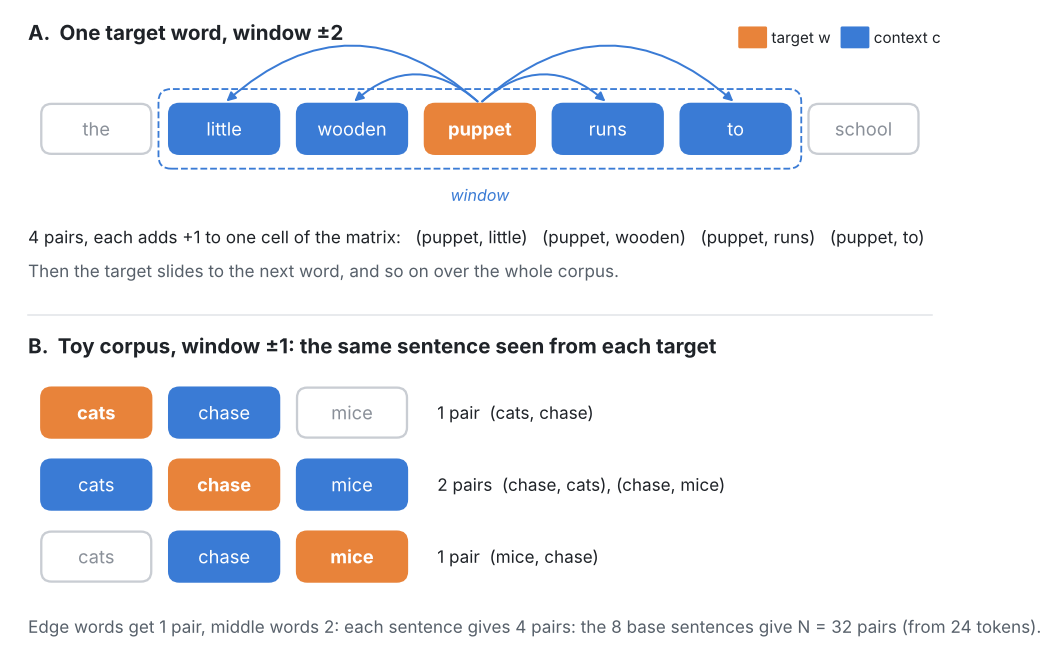

Panel B also shows something we will need for PPMI in Section 1.3: an occurrence in the middle of a sentence produces more pairs than an occurrence at the edge.

This is already **vector semantics**: meaning becomes geometry.


In [4]:
# rows = target words; columns = context words; ==> word-context matrix
def build_cooccurrence(sentences, window=1):
    vocab = sorted({w for sent in sentences for w in sent})
    word_to_i = {w: i for i, w in enumerate(vocab)}
    matrix = np.zeros((len(vocab), len(vocab)), dtype=int)

    for sent in sentences:
        for i, target in enumerate(sent):
            left = max(0, i - window)
            right = min(len(sent), i + window + 1)
            for j in range(left, right):
                if i != j:
                    matrix[word_to_i[target], word_to_i[sent[j]]] += 1

    return vocab, word_to_i, matrix


vocab, word_to_i, cooc = build_cooccurrence(toy_tokens, window=1)
pd.DataFrame(cooc, index=vocab, columns=vocab)

,balls,bones,cats,chase,cheese,dogs,good,like,mice,milk,pasta,pizza,tastes,uses
balls,0,0,0,1,0,0,0,0,0,0,0,0,0,0
bones,0,0,0,0,0,0,0,1,0,0,0,0,0,0
cats,0,0,0,1,0,0,0,1,0,0,0,0,0,0
chase,1,0,1,0,0,1,0,0,1,0,0,0,0,0
cheese,0,0,0,0,0,0,0,0,0,0,0,0,0,2
dogs,0,0,0,1,0,0,0,1,0,0,0,0,0,0
good,0,0,0,0,0,0,0,0,0,0,0,0,2,0
like,0,1,1,0,0,1,0,0,0,1,0,0,0,0
mice,0,0,0,1,0,0,0,0,0,0,0,0,0,0
milk,0,0,0,0,0,0,0,1,0,0,0,0,0,0


### 🧬 Rows are vectors: our first word embeddings

Each **row** of the matrix above is the vector of a target word: its entry in column $c$ says how many times the word occurred next to the context word $c$. With the corpus as given, _cats_ is the vector with a 1 under _chase_, a 1 under _like_ and zeros elsewhere: exactly the same row as _dogs_.

- These are **count-based embeddings**, with one dimension per vocabulary word: `len(vocab)` dimensions here, hundreds of thousands in a real corpus.
- Every dimension is **interpretable** ("how often next to _chase_"), but most entries are 0: the vectors are **sparse**.
- With a symmetric window the matrix is symmetric: column $w$ is the same as row $w$.

Words with similar rows keep similar company. To turn "similar rows" into a number we need a similarity measure: the cosine.


## 📐 1.2 Cosine similarity: angle matters more than length

For vectors $u$ and $v$ of dimension $N$:

$$\cos(u,v)=\frac{u\cdot v}{\|u\|\,\|v\|}=\frac{\sum_{i=1}^{N} u_i v_i}{\sqrt{\sum_{i=1}^{N} u_i^2}\;\sqrt{\sum_{i=1}^{N} v_i^2}}$$

A value near 1 means the vectors point in a similar direction. A value near 0 means they are largely unrelated. With counts (never negative) the cosine is between 0 and 1; with dense embeddings it can also be negative.

Translation: **are these words keeping similar company?**

Why not simply the dot product? Because it grows with the length of the vectors, and frequent words have long count vectors: they would look similar to everything.


In [5]:
from sklearn.metrics.pairwise import cosine_similarity


def cos(a, b):
    a = np.asarray(a).reshape(1, -1)
    b = np.asarray(b).reshape(1, -1)
    if np.linalg.norm(a) == 0 or np.linalg.norm(b) == 0:
        return 0.0
    return float(cosine_similarity(a, b)[0, 0])


def toy_similarity(w1, w2):
    return cos(cooc[word_to_i[w1]], cooc[word_to_i[w2]])


for pair in [("cats", "dogs"), ("pizza", "pasta"), ("cats", "pizza")]:
    print(pair, round(toy_similarity(*pair), 3))

('cats', 'dogs') 1.0
('pizza', 'pasta') 1.0
('cats', 'pizza') 0.0


### 🧠 Checkpoint: play with the corpus

🎲 **Bet** before running the next cell: what is the closest word to `pizza` in our vocabulary?

Then go back to the toy corpus, add sentences, and re-run the cells from there:

1. Does adding the sentence `Gigi hates Gianni` change the semantics of `cats` and `dogs` (specifically, their cosine similarity)?
2. What about adding the sentence `Gigi hates pizza`? Will it change the semantics of `pizza`?
3. Devise a sentence that brings the cosine similarity between `pizza` and `pasta` back to `1.0`.
4. Devise a sentence that correlates the semantics of `cats` and `pizza`.


In [6]:
def nearest_in_toy(word, topn=5):
    scores = [
        (other, round(toy_similarity(word, other), 3))
        for other in vocab
        if other != word
    ]
    return sorted(scores, key=lambda x: x[1], reverse=True)[:topn]


nearest_in_toy("pizza")

[('pasta', 1.0),
 ('cheese', 0.707),
 ('good', 0.707),
 ('balls', 0.0),
 ('bones', 0.0)]

## 🧂 1.3 Too much salt: frequent words and PPMI

Real corpora are full of words like _the_, _of_ and _and_. They occur next to almost everything, so with raw counts almost every pair of words shares contexts and looks similar.

The fix is an old friend, **pointwise mutual information**: does a word $w$ occur with a context $c$ **more often than we would expect by chance**?

$$
\text{PMI}(w,c)=\log_2\frac{P(w,c)}{P(w)\,P(c)}
$$

The only question is _which probabilities_. Here the basic event is a **(target, context) pair**: one occurrence of a word $w$ with a word $c$ inside its window. Our co-occurrence matrix counts exactly these events: cell $C(w,c)$ is how many times the pair $(w, c)$ was observed, and

$$
N=\sum_{w}\sum_{c} C(w,c) = \text{total number of observed pairs (the sum of all cells)}.
$$

All three probabilities are computed on these same $N$ pairs:

$$
P(w,c)=\frac{C(w,c)}{N}, \qquad
P(w)=\frac{\sum_{c} C(w,c)}{N}\;(\text{row sum}), \qquad
P(c)=\frac{\sum_{w} C(w,c)}{N}\;(\text{column sum}).
$$

$P(w)$ is the probability that a randomly drawn pair has $w$ as its **target**; $P(c)$, that it has $c$ as its **context**.

> 🔍 **Why row sums and not just "how often $w$ occurs"?** A word in the middle of a sentence has neighbours on both sides, a word at the edge only on one, so different occurrences contribute different numbers of pairs. In the 8 base sentences of our toy corpus (window 1, panel B of the figure in Section 1.1), _cats_ and _chase_ both occur twice, but _cats_ is always at the edge (2 pairs) while _chase_ is always in the middle (4 pairs). Out of the $N = 32$ pairs, $P(\textit{chase}) = 4/32$ and $P(\textit{cats}) = 2/32$. Counting pairs keeps $P(w,c)$, $P(w)$ and $P(c)$ on the same footing, so that PMI is exactly 0 when $w$ and $c$ are independent.

> **The bigram PMI of the NLTK lab** is the PMI of the word-context matrix with the narrowest possible window: **one word to the left**. A symmetric $± L$ window simply counts about $2L$ pairs per token instead of one.

Finally, negative PMI values ("these two words avoid each other") are unreliable unless the corpus is enormous, so they are clipped to 0. This gives the **positive** PMI:

$$
\text{PPMI}(w,c)=\max\left(\log_2\frac{P(w,c)}{P(w)\,P(c)},\; 0\right)
$$


> 🔍 **Careful with $N$.** Here $N$ is the number of (target, context) **pairs**. In the tf-idf slides of Lecture 10, $N$ is the number of **documents**. Same letter, different counts.


In [7]:
def ppmi(counts):
    counts = [[float(c) for c in row] for row in counts]
    N = sum(sum(row) for row in counts)
    row_sums = [sum(row) for row in counts]
    col_sums = [sum(col) for col in zip(*counts)]
    result = []
    for i, row in enumerate(counts):
        new_row = []
        for j, c in enumerate(row):
            if c == 0:
                new_row.append(0.0)
            else:
                pmi = math.log2(c * N / (row_sums[i] * col_sums[j]))
                new_row.append(max(pmi, 0.0))
        result.append(new_row)
    return result

Let us see PPMI at work in a toy world where every noun keeps company with _the_.

> 🎲 **Bet:** with raw counts, how similar are `cats` and `pizza`? And with PPMI?


In [8]:
# A toy world where everybody meets "the"
the_sentences = [
    "the cats chase the mice",
    "the dogs chase the balls",
    "the cats like the milk",
    "the dogs like the bones",
    "the pizza tastes good",
    "the pasta tastes good",
    "the pizza uses the cheese",
    "the pasta uses the cheese",
]
the_vocab, the_ix, the_counts = build_cooccurrence(
    [s.split() for s in the_sentences], window=1
)

the_ppmi = np.asarray(ppmi(the_counts), dtype=float)
rows = []
for w1, w2 in [
    ("cats", "dogs"),
    ("pizza", "pasta"),
    ("cats", "pizza"),
    ("dogs", "cheese"),
    ("mice", "milk"),
]:
    rows.append({
        "pair": f"{w1} - {w2}",
        "cosine on raw counts": cos(the_counts[the_ix[w1]], the_counts[the_ix[w2]]),
        "cosine on PPMI": cos(the_ppmi[the_ix[w1]], the_ppmi[the_ix[w2]]),
    })
display(pd.DataFrame(rows).round(3))
print(
    "PPMI of the column 'the':",
    {
        w: round(float(the_ppmi[the_ix[w], the_ix["the"]]), 2)
        for w in ["cats", "pizza", "mice", "cheese"]
    },
)

,pair,cosine on raw counts,cosine on PPMI
0,cats - dogs,1.000,1.000
1,pizza - pasta,1.000,1.000
2,cats - pizza,0.667,0.045
3,dogs - cheese,0.816,0.212
4,mice - milk,1.000,1.000


PPMI of the column 'the': {'cats': 0.58, 'pizza': 0.58, 'mice': 1.58, 'cheese': 1.58}


🤔 **Discuss.**

- Why does `cats`–`pizza` collapse with PPMI, while `cats`–`dogs` stays at 1?
- `mice` and `milk` still have similarity 1 with PPMI. Why? Is that a bug of PPMI or a lack of data?


### 🔥 The PPMI matrix

Let us look at the two matrices of the "the" world side by side. With PPMI the **rows**, i.e. our word vectors, change:

- the column _the_ is no longer the darkest: every noun shares it, so for _cats_ or _pizza_ it carries little information (PPMI 0.6);
- the informative pairs stand out instead (_cats–chase_, _pizza–tastes_, _good–tastes_);
- a word seen only next to _the_ (_mice_, _milk_) keeps a high value there (1.6): for these words it is the only evidence we have.

The cosine similarities in the table above are computed exactly on these rows.


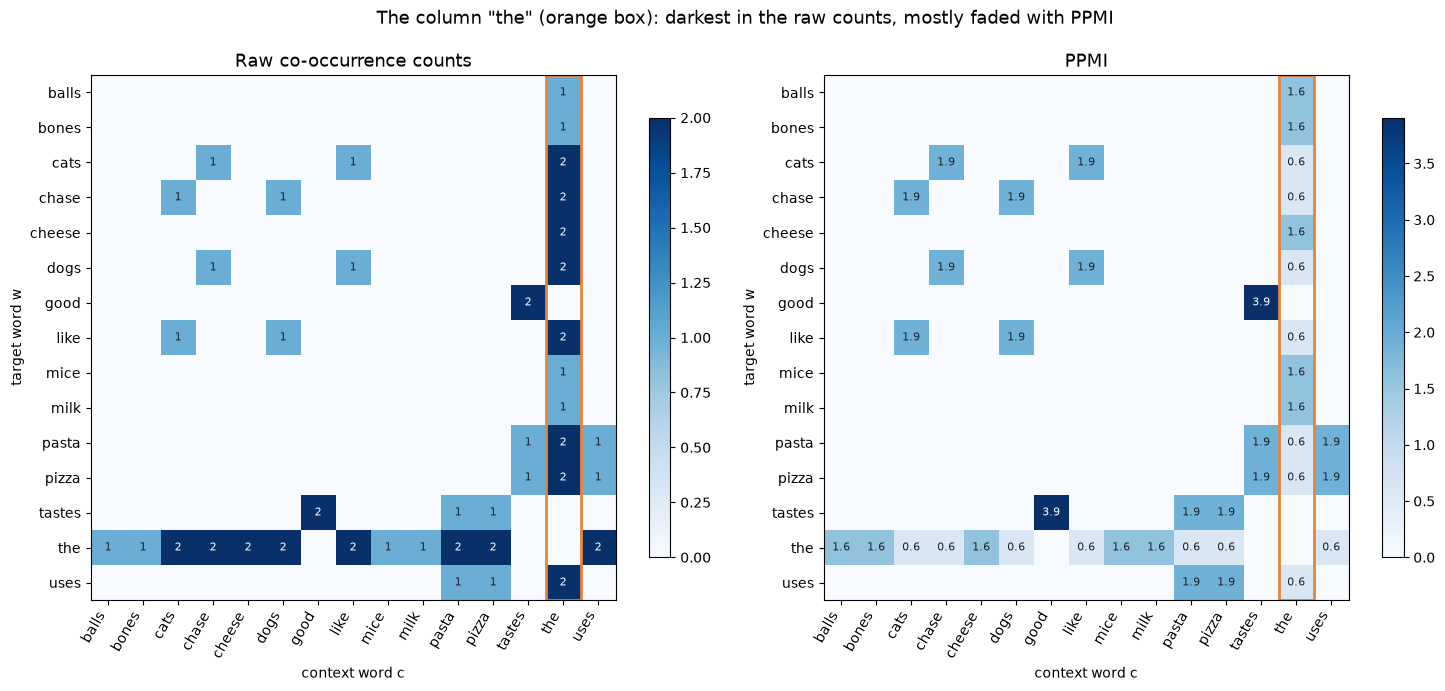

In [9]:
# Raw counts vs PPMI on the same toy world: each row is the vector of a target word
fig, axes = plt.subplots(1, 2, figsize=(15, 6.8))
panels = [
    (axes[0], the_counts.astype(float), "Raw co-occurrence counts", "{:.0f}"),
    (axes[1], the_ppmi, "PPMI", "{:.1f}"),
]
j_the = the_ix["the"]
for ax, M, title, fmt in panels:
    im = ax.imshow(M, cmap="Blues", vmin=0)
    ax.set_xticks(range(len(the_vocab)), the_vocab, rotation=60, ha="right")
    ax.set_yticks(range(len(the_vocab)), the_vocab)
    ax.set_xlabel("context word c")
    ax.set_ylabel("target word w")
    ax.set_title(title, fontsize=13)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if M[i, j] > 0:
                ax.text(
                    j,
                    i,
                    fmt.format(M[i, j]),
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white" if M[i, j] > 0.6 * M.max() else "#1F2328",
                )
    ax.add_patch(
        Rectangle((j_the - 0.5, -0.5), 1, M.shape[0], fill=False, ec="#E8833A", lw=2)
    )  # the column "the"
    fig.colorbar(im, ax=ax, shrink=0.75)
plt.suptitle(
    'The column "the" (orange box): darkest in the raw counts, mostly faded with PPMI',
    fontsize=13,
)
plt.tight_layout()
plt.show()

> 🔍 **PPMI with $\alpha = 0.75$.** Lecture 10 ends with a refinement: PMI is biased towards rare contexts, so the context probability is computed from counts raised to $\alpha = 0.75$, $P_\alpha(c) = \frac{\text{count}(c)^{\alpha}}{\sum_{c'} \text{count}(c')^{\alpha}}$. Rare contexts get a slightly higher probability, hence a lower PMI. For simplicity our `ppmi` uses plain PPMI. The same $\alpha = 0.75$ is used by word2vec to sample its negative examples (Section 2).


### 💡 What this toy model teaches us

- A word can be represented by its **distribution across contexts**.
- Similar context distributions create similar vectors.
- Raw counts are dominated by frequent words: **weighting** (PPMI, or TF-IDF for documents) matters.
- DRAWBACK: count vectors are interpretable, but **they grow with the vocabulary and are sparse** (mostly zeros).

Dense embeddings such as Word2Vec learn a compact representation (50–300 dimensions) instead of directly storing the full count matrix.


# 🪵 2. From sparse to dense. Train a tiny Word2Vec model on our recurring guest: Pinocchio!

We will use the Pinocchio novel to train a Word2Vec model.

Word2Vec learns vectors by solving a prediction task. In **skip-gram**, a center word is used to predict nearby context words; in **Continuous Bag of Words (CBOW)**, the surrounding context predicts the center word.

The useful vectors are a side effect of the training objective. This is one of machine learning's favorite tricks: **invent a task whose solution forces the representation you wanted all along**.

### 🎯 What skip-gram with negative sampling (SGNS) learns

Take a target word $w$ and a word $c$ that appears within the window around it. SGNS trains a tiny **logistic regression** (yes, the one of L06) that tells real (word, context) pairs from fake ones:

$$P(+\mid w,c)=\sigma(\mathbf{c}\cdot\mathbf{w}) = \frac{1}{1+e^{-\mathbf{c}\cdot\mathbf{w}}}$$

- **positive examples**: pairs $(w, c_{pos})$ that really occur in the text;
- **negative examples**: for each positive pair, $k$ pairs $(w, c_{neg})$ with $c_{neg}$ drawn at random from the vocabulary (frequent words more often, with probability $\propto \text{count}^{0.75}$).

Every word has **two** vectors: $\mathbf{w}$ when it is the target and $\mathbf{c}$ when it is a context. Training pushes $\mathbf{c}_{pos}\cdot\mathbf{w}$ up and $\mathbf{c}_{neg}\cdot\mathbf{w}$ down. Two words that appear with the same contexts are pushed towards the same context vectors, so they end up with similar embeddings: the distributional hypothesis again, now learned instead of counted. (🏋️ Exercise 2 implements this from scratch.)


### 🧩 So where are the embeddings?

After training, the **word embedding** of a word is its **target vector** $\mathbf{w}$: a row of the matrix $W$, which has $|V|$ rows and $d$ columns ($d$ = `vector_size`). The context matrix $C$ is a training device: it is common to throw it away and keep $W$, or to use $W + C$. In gensim, `pinocchio_w2v.wv["pinocchio"]` returns the row of $W$ for _pinocchio_.

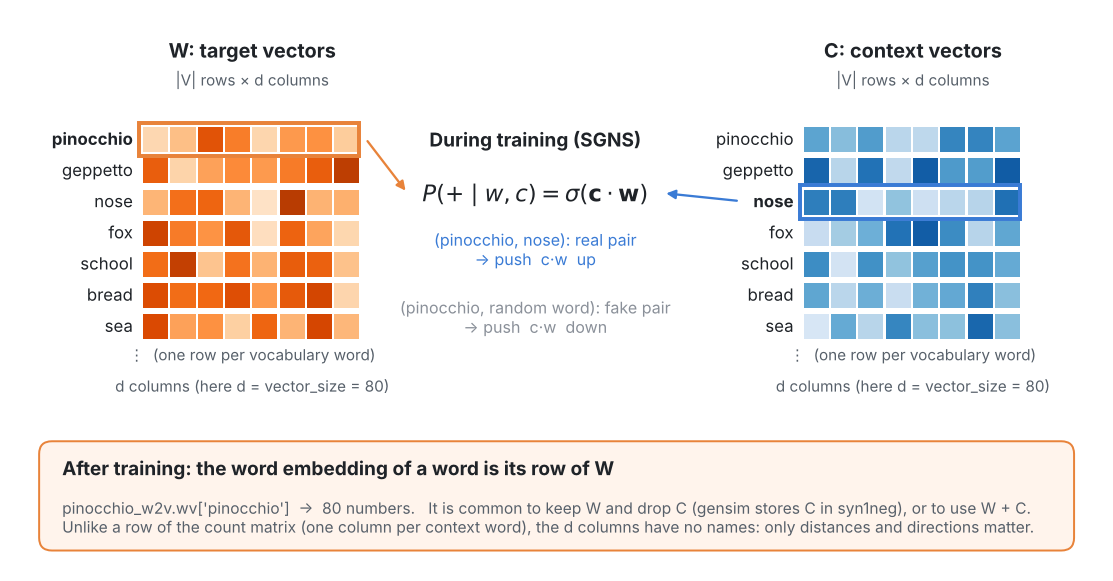

Compare with Section 1: a row of the count matrix has one interpretable column per context word ($|V|$ columns, mostly zeros); a row of $W$ has only $d$ = 50–300 columns, all non-zero and without names. These are **dense** embeddings: only distances and directions between rows carry meaning.


> 🔍 **W, or W + C?** As in Lecture 11, both choices are common: keep only the target vectors $W$, or add the two matrices. gensim keeps $W$: that is what `pinocchio_w2v.wv` contains.


In [10]:
# Download Pinocchio from Project Gutenberg
from gensim.models import Word2Vec

url_pinocchio = "https://www.gutenberg.org/files/500/500-0.txt"
text = requests.get(url_pinocchio, timeout=30).content.decode("utf-8", errors="ignore")
print(f"Downloaded {len(text):,} characters of wooden-puppet drama.")

Downloaded 239,501 characters of wooden-puppet drama.


This corpus will provide exceptionally good embeddings...
🤥 OK. That was a lie!
Our tiny corpus will not produce production-quality embeddings, but that is instructive: we can see what data scarcity looks like.


In [11]:
# One list of tokenised words per sentence
sentences = []
for sent in nltk.sent_tokenize(text):
    toks = [w.lower() for w in nltk.word_tokenize(sent) if w.isalpha()]
    if len(toks) >= 3:
        sentences.append(toks)

print("sentences:", len(sentences), "  tokens:", sum(len(s) for s in sentences))
print("example:", sentences[100][:20])

sentences: 3124   tokens: 42696
example: ['geppetto', 'do', 'not', 'insult', 'me', 'or', 'i', 'shall', 'call', 'you', 'polendina']


In [12]:
# Train Word2Vec (a few seconds)
pinocchio_w2v = Word2Vec(
    sentences=sentences,  # the corpus, a list of sentences, each a list of tokens
    vector_size=80,  # the number of dimensions d of each embedding
    window=10,  # the maximum distance between target and context
    min_count=2,  # words occuring fewer than 2 times are dropped from the vocabulary
    sg=1,  # 1 = skip-gram, 0 = CBOW
    epochs=20,
    seed=SEED,
)

print("Vocabulary size:", len(pinocchio_w2v.wv))
print("Vector size:", pinocchio_w2v.wv.vector_size)

Vocabulary size: 2182
Vector size: 80


In [13]:
for word in ["pinocchio", "father", "fox", "school", "hands"]:
    if word in pinocchio_w2v.wv:
        print(f"\nNeighbors of {word!r}:")
        print([
            (w, round(s, 3)) for w, s in pinocchio_w2v.wv.most_similar(word, topn=5)
        ])


Neighbors of 'pinocchio':
[('bravo', 0.654), ('burning', 0.649), ('joyfully', 0.639), ('frozen', 0.639), ('waver', 0.636)]

Neighbors of 'father':
[('comfort', 0.747), ('milk', 0.716), ('son', 0.713), ('spare', 0.704), ('saved', 0.672)]

Neighbors of 'fox':
[('cat', 0.923), ('blind', 0.793), ('repeated', 0.77), ('innkeeper', 0.75), ('leaned', 0.738)]

Neighbors of 'school':
[('succeed', 0.854), ('study', 0.83), ('sing', 0.774), ('pipes', 0.77), ('song', 0.768)]

Neighbors of 'hands':
[('clapped', 0.8), ('shook', 0.774), ('crossed', 0.761), ('swore', 0.745), ('wig', 0.734)]


### 🔬 Mini-experiment: the corpus and the hyperparameters matter

Change one thing at a time in the training cell and inspect neighbours again:

- `window` (2 = local, syntactic neighbors; 10 = broader, topical neighbors),
- `min_count` ,
- `sg=1` vs `sg=0` ,
- `epochs`.

🤔 **Discuss.**

- Can you tell why with `window=2`, the neighbors of `hands` are more "body"-like words while for `window=10` neighbors are more "scene"-like words involving hands?
- which one is faster between `sg=1` (skip-gram) and `sg=0` (CBOW)? Can you tell why?


# 🧠 3. Pre-trained embeddings: borrowing a much larger linguistic memory

Training on one book is charming but limited. We now load embeddings pre-trained by someone else on billions of words.

For class speed, the default is **GloVe 100d** (_Global Vectors_, Stanford; trained on Wikipedia + Gigaword: 6 billion tokens, 400k words, lowercased, 128 MB).

> 🔍 **GloVe is not word2vec**, but it lives halfway between the two worlds we have seen:
>
> - like the **count-based** models of Section 1, it first builds a word–context co-occurrence matrix $X$ over the whole corpus;
> - like **word2vec** in Section 2, it then _learns_ short dense vectors, here by asking that the dot product of a word vector and a context vector approximates the log of their co-occurrence count, $\mathbf{w}\cdot\mathbf{c} \approx \log X_{wc}$.
>
> Different recipe, same raw material: co-occurrence statistics. That is why, for us, GloVe vectors behave much like word2vec ones.

If you want a true word2vec model, flip the flag below to load the **Google News Word2Vec** vectors (300d, trained on ~100 billion words, ~1.6 GB): much larger and slower to download.

Both models are **static embeddings**: each vocabulary item has exactly one stored vector. Below I use GloVe.


> 🔍 **And fastText?** Lecture 11 also presents **fastText**: skip-gram on a word _and_ its character n-grams (3 to 6 characters). Its advantage is that it can build a vector for a word never seen in training, from its n-grams. GloVe and word2vec cannot: try `emb["pinocchiesque"]`. gensim can train it with `gensim.models.FastText`, used exactly like `Word2Vec`.


In [14]:
# Download GloVe (≈ 1 min), word2vec-google-news (≈ 7 mins)
import gensim.downloader as api

USE_LARGE_GOOGLE_NEWS = False
model_name = (
    "word2vec-google-news-300" if USE_LARGE_GOOGLE_NEWS else "glove-wiki-gigaword-100"
)
print("Loading:", model_name)
emb = typing.cast(gensim.models.keyedvectors.KeyedVectors, api.load(model_name))
print("Loaded", len(emb), "vectors of dimension", emb.vector_size)
print("The vector of 'pizza' starts with", np.round(emb["pizza"][:8], 3), "...")

Loading: glove-wiki-gigaword-100
Loaded 400000 vectors of dimension 100
The vector of 'pizza' starts with [ 0.228  0.045 -0.555 -0.003 -0.037  0.463  0.998 -0.508] ...


## 💕 3.1 Nearest neighbors: semantic speed dating

The model has no dictionary definition. It only knows geometry learned from corpus statistics.


In [15]:
for word in ["car", "computer", "pizza", "language"]:
    print(f"\n{word.upper()} ->")
    print([(w, round(s, 3)) for w, s in emb.most_similar(word, topn=5)])


CAR ->
[('vehicle', 0.863), ('truck', 0.86), ('cars', 0.837), ('driver', 0.819), ('driving', 0.781)]

COMPUTER ->
[('computers', 0.875), ('software', 0.837), ('technology', 0.764), ('pc', 0.737), ('hardware', 0.729)]

PIZZA ->
[('sandwich', 0.749), ('sandwiches', 0.722), ('bread', 0.701), ('pizzas', 0.7), ('burger', 0.698)]

LANGUAGE ->
[('languages', 0.826), ('word', 0.746), ('spoken', 0.738), ('arabic', 0.732), ('english', 0.721)]


### 🔬 Again on corpus matters

Let us inspect `pinocchio`, `father`, `fox`, `school` and `hands` again.

The embeddings should be more reliable and closer to our intuitive "common sense".
Notice how different the results are from the model trained only on Pinocchio!


In [16]:
for word in ["pinocchio", "father", "fox", "school", "hands"]:
    print(f"\n{word.upper()} ->")
    print([(w, round(s, 3)) for w, s in emb.most_similar(word, topn=5)])


PINOCCHIO ->
[('geppetto', 0.666), ('bambi', 0.577), ('rapunzel', 0.577), ('snowman', 0.553), ('collodi', 0.55)]

FATHER ->
[('son', 0.924), ('brother', 0.922), ('grandfather', 0.883), ('mother', 0.866), ('uncle', 0.865)]

FOX ->
[('abc', 0.796), ('nbc', 0.778), ('cbs', 0.756), ('television', 0.736), ('tv', 0.709)]

SCHOOL ->
[('college', 0.885), ('schools', 0.836), ('elementary', 0.816), ('students', 0.803), ('student', 0.781)]

HANDS ->
[('hand', 0.834), ('face', 0.701), ('fingers', 0.7), ('away', 0.698), ('down', 0.695)]


### 🦊 One word, different meanings

Notice something interesting about `fox`?

In the Pinocchio model, `fox` relates to the story's characters and actions.
In GloVe 100d, `fox` relates to television networks (ABC, NBC, CBS).

The word "fox" has different _dominant_ senses depending on what corpus
trained the embeddings. In Pinocchio's small corpus, the character "Fox"
dominates. In Wikipedia + web text, the TV network "Fox" dominates.

This shows that embeddings capture **what the corpus emphasizes**,
not some universal "true meaning."

This is called **polysemy**: one word with multiple meanings. Embeddings
capture whichever meaning is most frequent in their training corpus.
A corpus matters not just for _reliability_, but for _which sense_ of a
word gets learned.

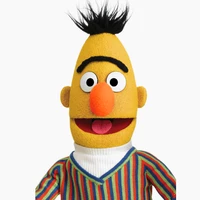

### 🤖 Contextual embeddings

Traditional embeddings like Word2Vec and GloVe assign **one fixed vector to each word**. So every occurrence of `fox` gets the same embedding, whether it refers to an animal, a story character, or a television network.

Transformers take a different approach: they produce an embedding for **each occurrence of a word based on its surrounding context**.

For example, `fox` can receive different representations in:

- _The **fox** ran through the forest._
- _The **Fox** tricked Pinocchio._
- _The game was broadcast on **Fox**._

These are called **contextual embeddings**. Instead of asking _“What does the word `fox` mean in general?”_, the model can represent _“What does `fox` mean here?”_

This ability to represent words differently depending on context is one of the major advantages of transformer-based language models over traditional static embeddings.


## 🕵 3.2 The odd-one-out game

One word walks into the wrong semantic neighborhood. Find the intruder.

A simple strategy: compute the **mean vector** of the group (its "center of mass"). The intruder is the word whose vector is least similar to the center.


In [17]:
def odd_one_out(words):
    vectors = [emb[w] for w in words]
    center = np.mean(vectors, axis=0)
    sims = [cos(v, center) for v in vectors]
    return words[sims.index(min(sims))]

### 🎯 Fool the model

Create odd-one-out sets that **fool the model** or produce a debatable answer. Write down the answer you expect before running.

This is more interesting than getting the obvious examples right: failures reveal what the embedding space actually captured.


In [18]:
# ✍️ Your sets: write the answer you expect as a comment
fool_sets = [
    ["fox", "cat", "dog", "whale"],  # expected: ?
    # add your sets here
]

for words in fool_sets:
    missing = [w for w in words if w not in emb]
    print(
        words,
        "->",
        f"not in the vocabulary: {missing}" if missing else odd_one_out(words),
    )

['fox', 'cat', 'dog', 'whale'] -> fox


## 🧮 3.3 Vector arithmetic and analogies

The famous example is:

`king - man + woman -> queen`

This works because some relations are approximately encoded as directions in the embedding space: the offset $\mathbf{king}-\mathbf{man}$ is close to $\mathbf{queen}-\mathbf{woman}$. But do not turn one successful analogy into a religion: results vary with model, corpus, vocabulary, and relation.


> 🔍 **Which distance?** Lecture 11 writes the parallelogram method as the word $x$ that minimizes a distance from $\mathbf{b}-\mathbf{a}+\mathbf{a}^*$, "such as the Euclidean distance". gensim, and our code below, rank the words by **cosine** instead. For word vectors of length 1 (gensim normalizes them) the two give the same ranking.


In [19]:
def gensim_analogy(model, a, b, c, topn=5):
    # A:B :: C:D reads in Natural Language Processing as A is to B as C is to D
    # This means in Linear Algebra terms that  B - A = D - C  =>  D = B - A + C
    return [
        (w, round(s, 3))
        for w, s in model.most_similar(positive=[b, c], negative=[a], topn=topn)
    ]


print("man : king :: woman : ?")
print(gensim_analogy(emb, "man", "king", "woman"))

print("\ngermany : hitler :: italy : ?")
print(gensim_analogy(emb, "germany", "hitler", "italy"))

man : king :: woman : ?
[('queen', 0.77), ('monarch', 0.684), ('throne', 0.676), ('daughter', 0.659), ('princess', 0.652)]

germany : hitler :: italy : ?
[('mussolini', 0.827), ('fascist', 0.685), ('stalin', 0.667), ('adolf', 0.626), ('napoleon', 0.582)]


### 🔧 Analogies by hand

`most_similar` hides a detail. Let us open the box. Below we write `analogy(a, b, c, topn=5, exclude_inputs=True)`, a function that given `a`, `b`, `c`, it outputs the `topn` words whose vectors is closest to $\mathbf{b} - \mathbf{a} + \mathbf{c}$. Importantly, when `exclude_inputs=True`, the words `a`, `b`, `c` must not appear in the list.

> 🎲 **Bet:** what will `analogy("man", "king", "woman", topn=3, exclude_inputs=False)` return?


In [20]:
VOCAB_50K = emb.index_to_key[
    :50000
]  # GloVe lists its words from the most to the least frequent
_M50 = np.vstack([emb[w] for w in VOCAB_50K])
_M50 = _M50 / np.linalg.norm(_M50, axis=1, keepdims=True)


def similarities_to(vec):
    # cosine similarity between vec and each word of VOCAB_50K (a NumPy array of 50,000 numbers)
    vec = np.asarray(vec, dtype=float)
    return _M50 @ (vec / np.linalg.norm(vec))


scores = similarities_to(emb["pizza"])
print(
    "similarity of 'pizza' with the first 5 words of VOCAB_50K:",
    list(zip(VOCAB_50K[:5], np.round(scores[:5], 3))),
)

similarity of 'pizza' with the first 5 words of VOCAB_50K: [('the', np.float64(0.198)), (',', np.float64(0.22)), ('.', np.float64(0.233)), ('of', np.float64(0.161)), ('to', np.float64(0.175))]


In [21]:
def analogy(a, b, c, topn=5, exclude_inputs=True):
    target = emb[b] - emb[a] + emb[c]
    scores = similarities_to(target)
    result = []
    for i in np.argsort(-scores):
        word = VOCAB_50K[i]
        if exclude_inputs and word in (a, b, c):
            continue
        result.append((word, float(scores[i])))
        if len(result) == topn:
            break
    return result

In [22]:
# What happens without the exclusion?
queries = [
    ("man", "king", "woman"),
    ("france", "paris", "italy"),
    ("good", "better", "bad"),
    ("mouse", "mice", "child"),
    ("walk", "walked", "swim"),
    ("big", "bigger", "small"),
]

rows = []
for a, b, c in queries:
    rows.append({
        "a : b :: c : ?": f"{a} : {b} :: {c} : ?",
        "inputs excluded": ", ".join(w for w, _ in analogy(a, b, c, topn=3)),
        "inputs allowed": ", ".join(
            w for w, _ in analogy(a, b, c, topn=3, exclude_inputs=False)
        ),
        "gensim most_similar": ", ".join(
            w
            for w, _ in emb.most_similar(
                positive=[b, c], negative=[a], topn=3, restrict_vocab=50000
            )
        ),
    })
display(pd.DataFrame(rows))

,a : b :: c : ?,inputs excluded,inputs allowed,gensim most_similar
0,man : king :: woman : ?,"queen, monarch, throne","king, queen, monarch","queen, monarch, throne"
1,france : paris :: italy : ?,"rome, milan, naples","rome, milan, italy","rome, milan, naples"
2,good : better :: bad : ?,"worse, too, getting","bad, worse, better","worse, too, even"
3,mouse : mice :: child : ?,"children, pregnant, infants","child, children, pregnant","children, pregnant, infants"
4,walk : walked :: swim : ?,"swam, swimming, drowned","swim, swam, swimming","swam, swimming, drowned"
5,big : bigger :: small : ?,"larger, smaller, large","larger, smaller, small","larger, smaller, large"


🤔 **Discuss.**

- Without the exclusion, which word wins most of the time? Why is that geometrically unavoidable when the offset $\mathbf{b}-\mathbf{a}$ is small?
- `gensim` excludes the inputs too (and normalizes the three vectors before combining them). How much of the famous analogy results is due to this rule?
- `big : bigger :: small : ?`: is `larger` a failure of the embedding or of the evaluation?


### 🔬 Analogy lab

Try relations of different kinds and keep track of both **successes and embarrassing failures**:

- capital-country,
- singular-plural,
- comparative-superlative,
- profession-action,
- domain-specific terms.


In [23]:
# ✍️ Your analogies: gensim_analogy(emb, a, b, c) or your analogy(a, b, c)
print(gensim_analogy(emb, "good", "best", "bad"))

[('worst', 0.698), ('movie', 0.667), ('big', 0.665), ('ever', 0.657), ('film', 0.638)]


# 🗺 4. Visualizing an embedding space

A 100- or 300-dimensional space does not fit on a lecture projector. PCA gives us a 2D projection.

**Warning:** the plot is a projection, not the full geometry. Two dots looking close in 2D does not prove that the original high-dimensional vectors are equally close.


> 🔍 **PCA or t-SNE?** Lecture 11 mentions **t-SNE**, the most common projection for embeddings. Here we use **PCA**, a linear projection: fast and deterministic. t-SNE is non-linear and preserves local neighbourhoods better, but distances between far clusters are not meaningful and the picture changes with the random seed. Try it with `sklearn.manifold.TSNE`.


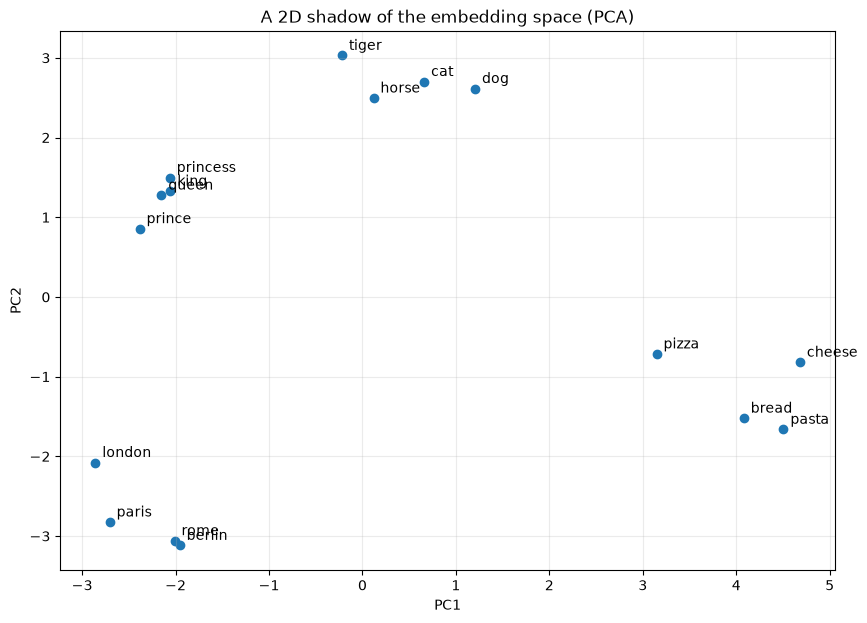

In [24]:
def plot_words(model, words):
    words = [w for w in words if w in model]
    vectors = np.vstack([model[w] for w in words])
    xy = PCA(n_components=2).fit_transform(vectors)

    plt.figure(figsize=(10, 7))
    plt.scatter(xy[:, 0], xy[:, 1])
    for word, (x, y) in zip(words, xy):
        plt.annotate(word, (x, y), xytext=(5, 4), textcoords="offset points")
    plt.title("A 2D shadow of the embedding space (PCA)")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()


plot_words(
    emb,
    [
        "king",
        "queen",
        "prince",
        "princess",
        "dog",
        "cat",
        "horse",
        "tiger",
        "rome",
        "paris",
        "london",
        "berlin",
        "pizza",
        "pasta",
        "bread",
        "cheese",
    ],
)

# 🧳 5. Embeddings have baggage

Static embeddings learn from human-produced corpora. That means they can encode useful regularities and **social stereotypes or other undesirable associations**.

The next experiment is deliberately simple: compare a few profession words with `woman` and `man`. Do **not** interpret the result as truth about occupations. Interpret it as evidence about associations present in the training data and model.


In [25]:
professions = [
    "engineer",
    "nurse",
    "teacher",
    "scientist",
    "programmer",
    "doctor",
    "receptionist",
    "manager",
]

rows = []
for p in professions:
    sim_w, sim_m = cos(emb[p], emb["woman"]), cos(emb[p], emb["man"])
    rows.append({
        "profession": p,
        "sim_woman": sim_w,
        "sim_man": sim_m,
        "woman_minus_man": sim_w - sim_m,
    })

bias_df = pd.DataFrame(rows).sort_values("woman_minus_man", ascending=False)
bias_df.round(3)

,profession,sim_woman,sim_man,woman_minus_man
1,nurse,0.614,0.456,0.158
6,receptionist,0.336,0.190,0.147
2,teacher,0.579,0.526,0.054
5,doctor,0.633,0.609,0.024
3,scientist,0.384,0.437,-0.053
4,programmer,0.201,0.265,-0.063
0,engineer,0.334,0.430,-0.096
7,manager,0.242,0.456,-0.214


A famous example (Bolukbasi et al., 2016) is the analogy _man : computer programmer :: woman : homemaker_.


### 🤔 Discussion

- Why can a biased representation affect downstream classifiers or ranking systems (e.g., a CV-screening tool)?
- Would simply deleting a few words fix the problem? (🏋️ Exercise 4 tries something smarter.)

A useful engineering habit is to evaluate representations not only on **accuracy**, but also on the behavior we do not want.


# 🏦 6. Static embeddings cannot read the room

A static embedding stores **one vector per vocabulary item**. Therefore `bank` has the same vector in:

- `I deposited money at the bank.`
- `We sat on the river bank.`

So what does that single vector contain? Roughly a **frequency-weighted blend of all the senses** of the word: in news and Wikipedia text the financial sense wins by far.

> 🎲 **Bet:** are there any river words among the 10 nearest neighbors of `bank`?


In [26]:
print("bank ->", [w for w, _ in emb.most_similar("bank", topn=10)])

bank -> ['banks', 'banking', 'credit', 'investment', 'financial', 'securities', 'lending', 'funds', 'ubs', 'finance']


The river sense is hidden in the vector.


In [27]:
for w in ["loan", "money", "shore", "river"]:
    print(f"cos(bank, {w}) = {cos(emb['bank'], emb[w]):.3f}")

cos(bank, loan) = 0.551
cos(bank, money) = 0.572
cos(bank, shore) = 0.511
cos(bank, river) = 0.334


Can we steer _bank_ towards its river sense? Subtracting _money_ alone is not enough (try it!): we also need to add _river_.


In [28]:
print(
    "bank - money + river ->",
    [
        w
        for w, _ in emb.most_similar(
            positive=["bank", "river"], negative=["money"], topn=6
        )
    ],
)
for w in ["loan", "money", "shore", "river"]:
    print(f"cos(bank, {w}) = {cos(emb['bank'], emb[w]):.3f}")

bank - money + river -> ['danube', 'estuary', 'rivers', 'rhine', 'tigris', 'meuse']
cos(bank, loan) = 0.551
cos(bank, money) = 0.572
cos(bank, shore) = 0.511
cos(bank, river) = 0.334


Nice, but the model cannot choose a different vector based on a specific sentence.

Again, this is another bridge to **contextual embeddings**: in transformer models, the token representation will be updated through the attention blovks updated using the surrounding tokens.


# 🥣 7. From words to sentences: the suspiciously simple average

A quick document representation is to average the vectors of its known words. This loses order, syntax, negation structure, and a great deal of nuance; nonetheless, it is a surprisingly useful baseline.


In [29]:
TOKEN_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")


def tokenize_simple(text):
    return TOKEN_RE.findall(text.lower())


def mean_embedding(model, text):
    words = [w for w in tokenize_simple(text) if w in model]
    if not words:
        return np.zeros(model.vector_size, dtype=float)
    return np.mean([model[w] for w in words], axis=0)


def sentence_similarity(model, s1, s2):
    return cos(mean_embedding(model, s1), mean_embedding(model, s2))


pairs = [
    ("A dog is running in the park", "A puppy runs outside"),  # similar meaning
    ("I love this movie", "This film is fantastic"),  # similar sentiment
    (
        "I love this movie",
        "Quantum mechanics studies physical systems",
    ),  # different topics
    ("The movie is good", "The movie is not good"),  # opposite sentiment
]

for a, b in pairs:
    print(round(sentence_similarity(emb, a, b), 3), "|", a, "<->", b)

0.906 | A dog is running in the park <-> A puppy runs outside
0.904 | I love this movie <-> This film is fantastic
0.441 | I love this movie <-> Quantum mechanics studies physical systems
0.991 | The movie is good <-> The movie is not good


### 🧠 Checkpoint: spot the weakness

Pay special attention to `The movie is good` vs `The movie is not good`.

The two sentences are almost identical when you average. Both have `the`, `movie`, `is`, `good`; the only difference is `not`, which is just one extra vector, diluted into the mean.

Averaging can keep the two vectors very close even though the sentiment flips. Word order and composition matter.


# 🥊 8. Sentiment classification battle: dense vs sparse

Back to the movie-review task of the NLTK lab (1000 positive and 1000 negative reviews), with two new contenders:

1. **Mean pre-trained embeddings** → dense vector (100 numbers) → Logistic Regression.
2. **TF-IDF** → sparse vector (12,000 numbers) → Logistic Regression.

Important: TF-IDF is fitted **only on the training split**. Fitting it on all documents before the split leaks information from the test set.


In [30]:
from nltk.corpus import movie_reviews
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

docs, labels = [], []
for label in movie_reviews.categories():
    for fileid in movie_reviews.fileids(label):
        docs.append(" ".join(movie_reviews.words(fileid)))
        labels.append(1 if label == "pos" else 0)

labels = np.asarray(labels)
indices = np.arange(len(docs))
train_idx, test_idx = train_test_split(
    indices, test_size=0.2, random_state=SEED, stratify=labels
)

train_texts = [docs[i] for i in train_idx]
test_texts = [docs[i] for i in test_idx]
y_train = labels[train_idx]
y_test = labels[test_idx]

print(len(train_texts), "train reviews,", len(test_texts), "test reviews")

1600 train reviews, 400 test reviews


## 🧮 8.1 Contender A: mean word embeddings

Using our `mean_embedding` function, each review becomes one dense vector. Words absent from the pre-trained vocabulary are skipped.


In [31]:
def embed_documents(model, texts):
    return np.vstack([mean_embedding(model, t) for t in tqdm(texts)])


X_train_emb = embed_documents(emb, train_texts)
X_test_emb = embed_documents(emb, test_texts)

clf_emb = LogisticRegression(max_iter=2000, random_state=SEED)
clf_emb.fit(X_train_emb, y_train)
pred_emb = clf_emb.predict(X_test_emb)
acc_emb = accuracy_score(y_test, pred_emb)
print("Mean-embedding accuracy:", round(acc_emb, 4))

  0%|          | 0/1600 [00:00<?, ?it/s]

  0%|          | 0/400 [00:00<?, ?it/s]

Mean-embedding accuracy: 0.7325


Considering how simple this model is, not bad this test accuracy!


## 👔 8.2 Contender B: TF-IDF

TF-IDF does not understand semantic similarity directly, but it preserves highly discriminative lexical features. Never underestimate a strong baseline wearing a boring suit.

### ⚙️ How a review becomes a TF-IDF vector

**1. Features.** From the _training_ reviews we collect every unigram and bigram (`ngram_range=(1, 2)`: _good_, _not good_, ...), drop those that appear in fewer than 2 reviews (`min_df=2`) and keep the 12,000 most frequent (`max_features`). Each review $d$ becomes a vector with one entry per feature (term) $t$.

**2. Term frequency (TF):** how much $t$ matters _in this review_. With $\text{count}(t,d)$ the number of occurrences of $t$ in $d$ (Lecture 10, J&M Ch. 11):

$$
\text{tf}_{t,d} = \begin{cases} 1 + \log_{10} \text{count}(t,d) & \text{if } \text{count}(t,d) > 0 \\ 0 & \text{otherwise} \end{cases}
$$

The log dampens repetition: a word used 10 times weighs 2, used 100 times weighs 3, not 100.

**3. Inverse document frequency (IDF):** how rare, hence informative, $t$ is _across the collection_. With $N$ the number of documents (here the 1,600 training reviews) and $\text{df}_t$ the number of documents that contain $t$:

$$
\text{idf}_t = \log_{10}\frac{N}{\text{df}_t}
$$

A term that occurs in every document gets idf 0: it does not help to tell documents apart.

**4. TF-IDF:** the product of the two,

$$
\text{tf-idf}(t,d) = \text{tf}_{t,d} \cdot \text{idf}_t ,
$$

high for terms that are frequent in this review and rare in the others. The vector of all the $\text{tf-idf}(t,d)$ values is the representation of review $d$.

The document vector is then fed to logistic regression, exactly like the mean embedding. Compare the two recipes:

|             | document vector                                                                 | dimensions               | how words are combined                         |
| ----------- | ------------------------------------------------------------------------------- | ------------------------ | ---------------------------------------------- |
| Contender A | $x_d = \frac{1}{\lvert d \rvert}\sum_{w \in d} \mathbf{e}_w$ (known words only) | 100, shared by all words | every token counts the same                    |
| Contender B | $x_{d,t} = \text{tf}_{t,d}\cdot\text{idf}_t$                                    | 12,000, one per feature  | each feature weighted by how informative it is |

As said above, the features and the IDF values are learned on the training split only (`fit_transform`) and then applied to the test reviews (`transform`): n-grams that appear only in test reviews are ignored.


> 🔍 **scikit-learn vs the slides.** We use scikit-learn's `TfidfVectorizer`, whose formulas differ slightly from the ones above. With `sublinear_tf=True` it uses the natural log, $\text{tf}_{t,d} = 1 + \ln \text{count}(t,d)$, and a smoothed idf, $\text{idf}_t = \ln\frac{1+N}{1+\text{df}_t} + 1$ (so a term in every document gets idf 1 instead of 0); finally, each document vector is divided by its length (L2 normalization). The idea is the same: frequent in this document, rare in the others.


In [32]:
tfidf = TfidfVectorizer(
    ngram_range=(
        1,
        2,
    ),  # the features are single words and pairs of adjacent words, so *not good* becomes a feature of its own
    min_df=2,  # drop n-grams that occur in fewer than 2 documents
    max_features=12000,  # of the remaining n-grams, keep the 12k most frequent in the corpus
    sublinear_tf=True,  # use 1 + ln(tf) instead of the raw count
)

X_train_tfidf = tfidf.fit_transform(train_texts)
X_test_tfidf = tfidf.transform(test_texts)

clf_tfidf = LogisticRegression(max_iter=2000, random_state=SEED)
clf_tfidf.fit(X_train_tfidf, y_train)
pred_tfidf = clf_tfidf.predict(X_test_tfidf)
acc_tfidf = accuracy_score(y_test, pred_tfidf)
print("TF-IDF accuracy:", round(acc_tfidf, 4))

TF-IDF accuracy: 0.8725


> 🔍 **Rows or columns?** In the term-document matrix of Lecture 10 a document is a **column**. scikit-learn stores the transpose: `X_train_tfidf` has one **row** per review and one column per feature (1600 × 12000), which is the layout classifiers expect.


In [33]:
scoreboard = pd.DataFrame({
    "representation": ["Mean static embeddings", "TF-IDF 1-2 grams"],
    "dimensions": [X_train_emb.shape[1], X_train_tfidf.shape[1]],
    "test_accuracy": [acc_emb, acc_tfidf],
}).sort_values("test_accuracy", ascending=False)
scoreboard.round(4)

,representation,dimensions,test_accuracy
1,TF-IDF 1-2 grams,12000,0.8725
0,Mean static embeddings,100,0.7325


**Note:** in the NLTK lab, the _bag of words + logistic regression_ model obtaines similar test accuracy (0.868). Lexical features are hard to beat on this task.


### 🤔 Why might TF-IDF win?

Possible reasons:

- sentiment often depends on specific lexical cues (`excellent`, `awful`, ...);
- averaging embeddings washes out word order and local interactions;
- static embeddings are not tuned for the movie-review task;
- TF-IDF can keep rare but highly predictive terms.

### 💪 Why keep embeddings anyway?

They can transfer semantic information across related words, give compact dense representations, and become much more powerful when made contextual or fine-tuned. (🏋️ Exercise 3: how far can you push them?)


> 🔍 **Sparse beats dense here?** Lecture 11 says that dense vectors work better than sparse ones in NLP tasks, yet here the sparse TF-IDF wins. The culprit is not density but the **average**: a dense 100-dimensional compression of the TF-IDF vectors (truncated SVD, i.e. LSA) reaches about 0.86, while averaging word vectors loses the few strongly polar words of a review, even with word2vec trained on these very reviews (about 0.74).


TF-IDF classification report:
              precision    recall  f1-score   support

    negative     0.8744    0.8700    0.8722       200
    positive     0.8706    0.8750    0.8728       200

    accuracy                         0.8725       400
   macro avg     0.8725    0.8725    0.8725       400
weighted avg     0.8725    0.8725    0.8725       400



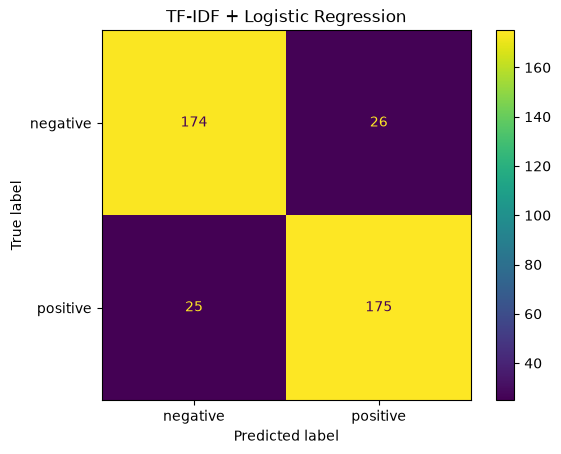

In [34]:
print("TF-IDF classification report:")
print(
    classification_report(
        y_test, pred_tfidf, target_names=["negative", "positive"], digits=4
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_tfidf, display_labels=["negative", "positive"]
)
plt.title("TF-IDF + Logistic Regression")
plt.show()

# 🗺 9. Take-away map

- **Count vectors**: meaning from co-occurrence; sparse and interpretable; **PPMI** tames frequent words.
- **Word2Vec/GloVe**: dense static vectors; similarity becomes geometry; SGNS = logistic regression on real vs fake (word, context) pairs.
- **Cosine similarity**: the workhorse for comparing directions.
- **Analogies**: some relations become directions, but results are not universal (and the inputs are excluded!).
- **Document averaging**: cheap and useful, but order/context disappear.
- **Bias**: embeddings inherit patterns from data.
- **Static limitation**: one word type = one vector, even when context changes.
- **TF-IDF**: still a formidable baseline.


# 🏋️ Exercises

Nothing is graded: it is just for fun and understanding.

Every exercise has a **TODO cell** (your code) followed by a **🧪 check cell** that tells you whether you got it right:

- ✅ correct · ❌ something is off (the message tells you what) · ⏳ not implemented yet

### 🧑‍💻 How to work on an exercise

1. Read the box **✏️ What you have to write**: it gives the name of the function, what goes in (**input**), what must come out (**output**), sometimes a hint, and a small **worked example** with the expected result.
2. Write your code in the cell marked `# ✏️ YOUR CODE HERE`, replacing `return None`, and run that cell.
3. Try your function by hand on the worked example, in a new cell.
4. Run the **🧪 check** cell right below. If you get ❌, read the message: it says which input went wrong, what you returned and what was expected. If you get ⏳, your function still returns `None`.

---

Pick the one you like most; the others are perfect homework. They are independent of each other, but they need the cells above (at least up to Section 8 for Exercise 3).

|      | Exercise                            | You will learn                                                        |
| ---- | ----------------------------------- | --------------------------------------------------------------------- |
| 🏋️ 1 | 🧑‍⚖️ Do embeddings agree with humans? | how embeddings are evaluated intrinsically; similarity vs relatedness |
| 🏋️ 2 | 🛠️ Word2Vec from scratch            | the SGNS loss and its gradients, by hand                              |
| 🏋️ 3 | 🥊 Beat the baseline                | feature engineering on dense vectors, and a regularization surprise   |
| 🏋️ 4 | 🧽 Can we wash the bias out?        | debiasing by projection, and its limits                               |


## 🧑‍⚖️ Exercise 1. Do embeddings agree with humans?

How do we know that an embedding is good, without a downstream task? We ask people to rate pairs of words on a scale, and we check whether the cosine similarities **rank** the pairs in the same order. Two classic datasets ship with gensim:

- **WordSim-353**: 353 pairs rated 0–10. The annotators were asked about _similarity_, but in practice they rated **relatedness**: _coffee–cup_ gets a high score.
- **SimLex-999**: 999 pairs rated 0–10 for **similarity** only: words that are related but not similar (_coffee–cup_, and antonyms like _happy–sad_) get low scores.

The standard metric is **Spearman's rank correlation** $\rho$: the Pearson correlation computed on the **ranks** of the values instead of the values themselves.

#### ✏️ What you have to write: `spearman(x, y)`

- **Input:** two lists of numbers `x` and `y` of the same length $n \ge 2$ (for us: human scores and cosine similarities).
- **Output:** a float, Spearman's $\rho$:
  1. replace each value of `x` by its rank (1 = smallest); **tied values get the average of the ranks they occupy**: `[10, 20, 20, 30]` → `[1, 2.5, 2.5, 4]`; same for `y`;
  2. return the Pearson correlation of the two lists of ranks: $r=\frac{\sum_i (a_i-\bar a)(b_i-\bar b)}{\sqrt{\sum_i (a_i-\bar a)^2}\sqrt{\sum_i (b_i-\bar b)^2}}$.
- Do not use `scipy`. Plain Python is enough.

**Worked example:**

- `spearman([1, 2, 3, 4], [10, 20, 30, 40])` → `1.0`; `spearman([1, 2, 3, 4], [40, 30, 20, 10])` → `-1.0`
- `spearman([1, 2, 3, 4, 5], [5, 6, 7, 8, 7])` → ranks `[1, 2, 3, 4, 5]` and `[1, 2, 3.5, 5, 3.5]` → `0.8208`

> 🎲 **Bet:** will GloVe agree more with humans on WordSim-353 or on SimLex-999? And the Pinocchio model?


In [35]:
# ✏️ YOUR CODE HERE (Exercise 1)
def rank(x):
    sorted_x = sorted(x)
    d = {i: [0, 0] for i in set(x)}
    for i, val in enumerate(sorted_x):
        d[val][0] += i
        d[val][1] += 1

    return np.array([d[i][0] / d[i][1] for i in x]) + 1


def spearman(x, y):
    """Input: two lists of numbers of the same length.
    Output: Spearman's rank correlation (a float). Ties get the average of their ranks."""
    x_ranks = rank(x)
    y_ranks = rank(y)

    x_mean = np.mean(x_ranks)
    y_mean = np.mean(y_ranks)
    num = np.sum((x_ranks - x_mean) * (y_ranks - y_mean))
    denom1 = np.sqrt(np.sum(np.pow(x_ranks - x_mean, 2)))
    denom2 = np.sqrt(np.sum(np.pow(y_ranks - y_mean, 2)))

    return num / (denom1 * denom2)

In [36]:
# 🧪 Check Exercise 1
_EX1_OK = False
try:
    if spearman([1, 2, 3], [1, 2, 3]) is None:
        _todo("Exercise 1")
    else:
        from scipy.stats import pearsonr, spearmanr

        problems = []
        for x_, y_, e_ in [
            ([1, 2, 3, 4], [10, 20, 30, 40], 1.0),
            ([1, 2, 3, 4], [40, 30, 20, 10], -1.0),
            ([1, 2, 3, 4, 5], [5, 6, 7, 8, 7], 0.8207827),
        ]:
            g_ = spearman(x_, y_)
            if not _close(g_, e_, tol=1e-5):
                problems.append(
                    f"spearman({x_}, {y_}): got {g_}, expected {round(e_, 4)}"
                )
                if x_[-1] == 5:
                    if _close(g_, pearsonr(x_, y_)[0], 1e-5):
                        problems.append(
                            "that is the Pearson correlation of the values: compute it on the RANKS"
                        )
                    else:
                        problems.append(
                            "the two 7s are tied: they must both get rank (3 + 4) / 2 = 3.5"
                        )
                break
        if not problems:
            if not _close(spearman([1, 2, 3], [1, 4, 9]), 1.0):
                problems.append(
                    "spearman([1, 2, 3], [1, 4, 9]) should be 1.0: any increasing relation has rho = 1 (are you using the ranks?)"
                )
            rng_ = np.random.default_rng(0)
            for _ in range(5):
                x_ = typing.cast(list, rng_.integers(0, 6, 30).tolist())
                y_ = typing.cast(list, rng_.normal(size=30).round(1).tolist())
                e_ = spearmanr(x_, y_).correlation
                if not _close(spearman(x_, y_), e_, tol=1e-5):
                    problems.append(
                        f"on random data with many ties: got {spearman(x_, y_):.4f}, expected {e_:.4f}"
                    )
                    break
        if problems:
            _fail(" | ".join(problems))
        else:
            _EX1_OK = True
            _ok("spearman agrees with scipy, ties included.")
except Exception as e:  # noqa: BLE001
    _err(e)

✅ spearman agrees with scipy, ties included.


In [37]:
# ▶️ Given: evaluate two models on two datasets
from gensim.test.utils import datapath


def read_pairs(filename):
    pairs = []
    with open(datapath(filename), encoding="utf-8") as file:
        for line in file:
            parts = line.strip().split("\t")
            if line.startswith("#") or len(parts) < 3:
                continue
            pairs.append((parts[0].lower(), parts[1].lower(), float(parts[2])))
    return pairs


DATASETS = {
    "WordSim-353": read_pairs("wordsim353.tsv"),
    "SimLex-999": read_pairs("simlex999.txt"),
}
MODELS = {"GloVe 100d": emb, "Pinocchio Word2Vec": pinocchio_w2v.wv}


def evaluate_similarity(model, pairs):
    human, machine = [], []
    for w1, w2, score in pairs:
        if w1 in model and w2 in model:  # pairs with unknown words are skipped
            human.append(score)
            machine.append(float(model.similarity(w1, w2)))
    rho = spearman(human, machine) if len(human) >= 3 else float("nan")
    return rho, len(human)


if not _EX1_OK:
    print("⏳ solve Exercise 1 first")
else:
    rows = []
    for m_name, model in MODELS.items():
        for d_name, pairs in DATASETS.items():
            rho, n = evaluate_similarity(model, pairs)
            rows.append({
                "model": m_name,
                "dataset": d_name,
                "Spearman rho": round(typing.cast(float, rho), 3),
                "pairs covered": f"{n} / {len(pairs)}",
            })
    display(pd.DataFrame(rows))

,model,dataset,Spearman rho,pairs covered
0,GloVe 100d,WordSim-353,0.533,353 / 353
1,GloVe 100d,SimLex-999,0.298,999 / 999
2,Pinocchio Word2Vec,WordSim-353,0.081,25 / 353
3,Pinocchio Word2Vec,SimLex-999,0.198,197 / 999


In [38]:
# ▶️ Given: where GloVe and the SimLex annotators disagree most
if _EX1_OK:
    pairs = [(a, b, s) for a, b, s in DATASETS["SimLex-999"] if a in emb and b in emb]
    sims = [float(emb.similarity(a, b)) for a, b, _ in pairs]
    h = np.argsort(np.argsort([s for _, _, s in pairs]))
    m = np.argsort(np.argsort(sims))
    gap = m - h
    print("GloVe finds them similar, humans do not:")
    for i in np.argsort(-gap)[:8]:
        print(
            f"   {pairs[i][0]:>10s} - {pairs[i][1]:<12s} human {pairs[i][2]:4.1f}/10   cosine {sims[i]:.2f}"
        )
    print("Humans find them similar, GloVe does not:")
    for i in np.argsort(gap)[:8]:
        print(
            f"   {pairs[i][0]:>10s} - {pairs[i][1]:<12s} human {pairs[i][2]:4.1f}/10   cosine {sims[i]:.2f}"
        )

GloVe finds them similar, humans do not:
       accept - reject       human  0.8/10   cosine 0.82
         easy - difficult    human  0.6/10   cosine 0.76
       shrink - grow         human  0.2/10   cosine 0.71
       forget - know         human  0.9/10   cosine 0.78
         lose - get          human  0.8/10   cosine 0.76
         hard - easy         human  0.9/10   cosine 0.77
        short - long         human  1.2/10   cosine 0.82
         keep - give         human  1.1/10   cosine 0.78
Humans find them similar, GloVe does not:
      creator - maker        human  9.6/10   cosine 0.24
        begin - originate    human  8.2/10   cosine 0.23
         crib - cradle       human  8.6/10   cosine 0.27
        think - rationalize  human  8.2/10   cosine 0.24
        plead - beg          human  9.1/10   cosine 0.32
       racket - noise        human  8.1/10   cosine 0.23
       bubble - suds         human  8.6/10   cosine 0.29
      alcohol - gin          human  8.7/10   cosine 0.29


🤔 **Discuss.**

- Why does GloVe agree more with humans on one dataset than on the other? Look at the pairs printed above: what kind of relation does the cosine of a distributional model reward?
- The Pinocchio model covers only some of the pairs: is its $\rho$ comparable with GloVe's?
- How would you change the training of a model (window size? corpus?) to get closer to SimLex?


## 🛠️ Exercise 2. Word2Vec from scratch

In Section 2 gensim trained skip-gram with negative sampling for us. Now you write the heart of it: the loss and the gradients for **one** positive pair $(w, c_{pos})$ and its $k$ negative samples $c_{neg_1}, \dots, c_{neg_k}$:

$$
L = -\log \sigma(\mathbf{c}_{pos}\cdot\mathbf{w}) \;-\; \sum_{i=1}^{k} \log \sigma(-\mathbf{c}_{neg_i}\cdot\mathbf{w})
$$

The first term wants $P(+\mid w, c_{pos}) = \sigma(\mathbf{c}_{pos}\cdot\mathbf{w})$ close to 1; the sum wants $P(-\mid w, c_{neg_i}) = 1 - \sigma(\mathbf{c}_{neg_i}\cdot\mathbf{w}) = \sigma(-\mathbf{c}_{neg_i}\cdot\mathbf{w})$ close to 1.

#### ✏️ What you have to write: `sgns_loss_and_gradients(w, c_pos, c_negs)`

- **Input:** NumPy arrays: `w` (the target vector, shape `(d,)`), `c_pos` (the positive context vector, shape `(d,)`), `c_negs` (the $k$ negative context vectors, one per row, shape `(k, d)`).
- **Output:** a tuple `(loss, grad_w, grad_c_pos, grad_c_negs)`: the loss $L$ (a float) and the gradients $\frac{\partial L}{\partial \mathbf{w}}$, $\frac{\partial L}{\partial \mathbf{c}_{pos}}$, $\frac{\partial L}{\partial \mathbf{c}_{neg_i}}$, with the same shapes as `w`, `c_pos` and `c_negs`.
- **Hints:** derive the gradients on paper first, using $\frac{d}{dz}\log\sigma(z) = 1-\sigma(z)$. `sigmoid` (below) works on arrays; `c_negs @ w` computes the $k$ dot products at once. The book gives the result, but try without it: the check cell compares your gradients with numerical derivatives, so it tells you whether your derivation is right.

**Worked example:** `w = [1, 0]`, `c_pos = [1, 0]`, `c_negs = [[0, 1]]`

- `loss` $= -\log\sigma(1) - \log\sigma(0) = 0.313 + 0.693 = 1.006$
- `grad_w = [-0.269, 0.5]`, `grad_c_pos = [-0.269, 0]`, `grad_c_negs = [[0.5, 0]]`

> 🎲 **Bet:** training starts with all context vectors equal to 0. What is the loss of every pair at the very beginning, with $k = 5$?


In [39]:
# ▶️ Given
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

In [ ]:
# ✏️ YOUR CODE HERE (Exercise 2)
def sgns_loss_and_gradients(w, c_pos, c_negs):
    """
    Input: w (d,), c_pos (d,), c_negs (k, d), NumPy arrays.
    Output: (loss, grad_w, grad_c_pos, grad_c_negs) the gradients with the
    shapes of w, c_pos, c_negs.
    """
    sig_pos = sigmoid(c_pos @ w)
    sig_negs = sigmoid(-c_negs @ w)
    loss = -np.log(sig_pos) - np.sum(np.log(sig_negs))

    grad_w_pos = -(1.0 - sig_pos) * c_pos

    term_negs = 1.0 - sig_negs
    grad_w_negs = term_negs @ c_negs

    grad_w = grad_w_pos + grad_w_negs
    grad_c_pos = -(1.0 - sig_pos) * w
    grad_c_negs = term_negs[:, np.newaxis] * w[np.newaxis, :]

    return (loss, grad_w, grad_c_pos, grad_c_negs)

In [75]:
# 🧪 Check Exercise 2
_EX2_OK = False
try:
    if sgns_loss_and_gradients(np.ones(2), np.ones(2), np.ones((1, 2))) is None:
        _todo("Exercise 2")
    else:
        problems = []
        out_ = sgns_loss_and_gradients(
            np.array([1.0, 0.0]), np.array([1.0, 0.0]), np.array([[0.0, 1.0]])
        )
        if len(out_) != 4:
            raise TypeError(
                f"return 4 values (loss, grad_w, grad_c_pos, grad_c_negs), you returned {len(out_)}"
            )
        l_, gw_, gp_, gn_ = out_
        exp_ = [1.006409, [-0.268941, 0.5], [-0.268941, 0.0], [[0.5, 0.0]]]
        for name_, g_, e_ in zip(
            ["loss", "grad_w", "grad_c_pos", "grad_c_negs"], out_, exp_
        ):
            g_ = np.asarray(g_, dtype=float)
            if g_.shape != np.shape(e_):
                problems.append(
                    f"worked example, {name_}: shape {g_.shape}, expected {np.shape(e_)}"
                )
            elif not np.allclose(g_, e_, atol=1e-4):
                hint_ = (
                    " (sign error?)"
                    if np.allclose(g_, -np.asarray(e_), atol=1e-4)
                    else ""
                )
                problems.append(
                    f"worked example, {name_}: got {np.round(g_, 3).tolist()}, expected {np.round(e_, 3).tolist()}{hint_}"
                )
        if not problems:  # numerical gradient check on random vectors
            rng_ = np.random.default_rng(1)
            w0, p0, n0 = (
                rng_.normal(size=6),
                rng_.normal(size=6),
                rng_.normal(size=(3, 6)),
            )
            _, gw_, gp_, gn_ = sgns_loss_and_gradients(w0, p0, n0)

            def num_grad(f, x, eps=1e-6):
                g = np.zeros_like(x)
                for idx in np.ndindex(x.shape):
                    x1 = x.copy()
                    x1[idx] += eps
                    x2 = x.copy()
                    x2[idx] -= eps
                    g[idx] = (f(x1) - f(x2)) / (2 * eps)
                return g

            L_ = lambda w, p, n: float(sgns_loss_and_gradients(w, p, n)[0])
            for name_, mine_, num_ in [
                ("grad_w", gw_, num_grad(lambda x: L_(x, p0, n0), w0)),
                ("grad_c_pos", gp_, num_grad(lambda x: L_(w0, x, n0), p0)),
                ("grad_c_negs", gn_, num_grad(lambda x: L_(w0, p0, x), n0)),
            ]:
                if not np.allclose(np.asarray(mine_, dtype=float), num_, atol=1e-4):
                    problems.append(
                        f"{name_} differs from the numerical derivative of your loss (random vectors, d = 6, k = 3)"
                    )
                    break
        if problems:
            _fail(" | ".join(problems))
        else:
            _EX2_OK = True
            _ok("loss and gradients are right (they match the numerical derivatives).")
except Exception as e:  # noqa: BLE001
    _err(e)

✅ loss and gradients are right (they match the numerical derivatives).


Now train your own SGNS on Pinocchio. The loop below does what gensim does internally, in plain NumPy: for each target word and each context word in the window, draw $k$ negatives, call **your** function, and take a gradient-descent step on the three vectors involved. Two classic tricks are included: negatives drawn with probability $\propto \text{count}^{0.75}$, and **subsampling** of very frequent words (_the_, _and_ are randomly dropped, so the window reaches further).


In [77]:
# ▶️ Given: train SGNS from scratch with your gradients (≈ 15–30 s)
def train_sgns(
    sentences,
    dim=50,
    window=2,
    k=5,
    epochs=5,
    lr0=0.05,
    min_count=3,
    t_sub=1e-3,
    seed=0,
):
    rng = np.random.default_rng(seed)
    counts = Counter(w for s in sentences for w in s)
    vocab = [w for w, c in counts.most_common() if c >= min_count]
    index = {w: i for i, w in enumerate(vocab)}
    freq = np.array([counts[w] for w in vocab], dtype=float)
    p_neg = freq**0.75 / np.sum(freq**0.75)  # negative sampling distribution
    keep = np.minimum(
        1.0, np.sqrt(t_sub / (freq / freq.sum())) + t_sub / (freq / freq.sum())
    )  # subsampling
    W = (rng.random((len(vocab), dim)) - 0.5) / dim  # target vectors: small random
    Cm = np.zeros((len(vocab), dim))  # context vectors: zeros
    data = [[index[w] for w in s if w in index] for s in sentences]
    for epoch in range(epochs):
        lr = lr0 * (1 - epoch / epochs)
        negatives = rng.choice(len(vocab), size=3_000_000, p=p_neg)
        pos_neg = 0
        total_loss, n_pairs = 0.0, 0
        for sent in data:
            sent = [i for i in sent if rng.random() < keep[i]]
            for pos, wi in enumerate(sent):
                for j in range(max(0, pos - window), min(len(sent), pos + window + 1)):
                    if j == pos:
                        continue
                    if pos_neg + k > len(negatives):
                        pos_neg = 0
                    negs = negatives[pos_neg : pos_neg + k]
                    pos_neg += k
                    loss, g_w, g_pos, g_negs = sgns_loss_and_gradients(
                        W[wi], Cm[sent[j]], Cm[negs]
                    )
                    W[wi] -= lr * g_w
                    Cm[sent[j]] -= lr * g_pos
                    np.subtract.at(Cm, negs, lr * np.asarray(g_negs))
                    total_loss += loss
                    n_pairs += 1
        print(
            f"epoch {epoch + 1}/{epochs}: mean loss {total_loss / n_pairs:.3f} on {n_pairs:,} pairs"
        )
    return vocab, index, W


if not _EX2_OK:
    print("⏳ solve Exercise 2 first")
else:
    my_vocab, my_index, my_W = train_sgns(sentences, window=5, k=15)
    my_Wn = my_W / np.linalg.norm(my_W, axis=1, keepdims=True)

    def my_neighbors(word, topn=6):
        sims = my_Wn @ my_Wn[my_index[word]]
        return [my_vocab[i] for i in np.argsort(-sims)[1 : topn + 1]]

    for word in ["pinocchio", "father", "fox", "school", "said", "cried"]:
        if word in my_index:
            print(f"{word:10s} yours: {my_neighbors(word)}")
            print(
                f"{'':10s} gensim: {[w for w, _ in pinocchio_w2v.wv.most_similar(word, topn=6)]}"
            )

epoch 1/5: mean loss 3.624 on 188,610 pairs
epoch 2/5: mean loss 3.401 on 188,890 pairs
epoch 3/5: mean loss 3.408 on 188,300 pairs
epoch 4/5: mean loss 3.414 on 188,958 pairs
epoch 5/5: mean loss 3.431 on 188,344 pairs
pinocchio  yours: ['geppetto', 'laughing', 'marionette', 'master', 'tears', 'dancing']
           gensim: ['bravo', 'burning', 'joyfully', 'frozen', 'waver', 'gallop']
father     yours: ['son', 'milk', 'comfort', 'friend', 'own', 'family']
           gensim: ['comfort', 'milk', 'son', 'spare', 'saved', 'playmates']
fox        yours: ['cat', 'met', 'repeated', 'let', 'throw', 'turning']
           gensim: ['cat', 'blind', 'repeated', 'innkeeper', 'leaned', 'met']
school     yours: ['study', 'succeed', 'ahead', 'careful', 'promise', 'want']
           gensim: ['succeed', 'study', 'sing', 'pipes', 'song', 'ahead']
said       yours: ['friend', 'saying', 'politely', 'showed', 'carpenter', 'owl']
           gensim: ['crow', 'laid', 'owl', 'saying', 'showed', 'brave']
cried   

🤔 **Discuss.**

- Was your bet on the initial loss right? Why does the loss decrease so little after the first epoch?
- Why two matrices (`W` and `Cm`) instead of one? What would go wrong with $\mathbf{c} = \mathbf{w}$ for the pair $(w, w)$?
- Change `window` to 5 and `k` to 15: what happens to the neighbors and to the training time?


## 🥊 Exercise 3. Beat the baseline

In Section 8 the mean of the GloVe vectors got **0.7325** accuracy, against **0.8725** for TF-IDF. Your mission: beat the 0.7325 accuracy by building a better **dense** document representation from the word embeddings. No check cell here: the evaluation cell is your referee and keeps a leaderboard of your attempts.

#### ✏️ What you have to write: `my_doc_vector(tokens)`

- **Input:** `tokens`, the list of lowercase words of a review (`tokenize_simple` output).
- **Output:** a 1D NumPy array of fixed length (the same for every review).
- You can also change `STANDARDIZE` (rescale every feature to mean 0 and variance 1 on the training set before the classifier) and `C` (the inverse of the regularization strength of `LogisticRegression`, default 1).

**Ideas** (one at a time, so you know what helped): weight the words, e.g. by their IDF (`IDF`, given below, is computed on the training reviews only); drop stopwords (`STOPWORDS`, given); describe the review with more statistics than the mean (`np.max`, `np.min` over the word vectors, concatenated with `np.concatenate`); look at the size of the numbers in your vectors, and remember that logistic regression is regularized (L06)...

> 🎲 **Bet:** which idea will help most?


In [78]:
# ▶️ Given: IDF on the training reviews, stopwords, and the referee
from nltk.corpus import stopwords
from sklearn.preprocessing import StandardScaler

nltk.download("stopwords", quiet=True)
STOPWORDS = set(stopwords.words("english"))

train_tokens = [tokenize_simple(t) for t in train_texts]
test_tokens = [tokenize_simple(t) for t in test_texts]
_df = Counter(w for toks in train_tokens for w in set(toks))
IDF = {
    w: math.log10(len(train_tokens) / c) for w, c in _df.items()
}  # idf as in Section 8.2; unseen words: use IDF.get(w, 0)

LEADERBOARD = {"mean embedding (Section 8)": acc_emb, "TF-IDF (Section 8)": acc_tfidf}


def evaluate_doc_vectors(doc_vector, name, standardize=False, C=1.0):
    X_tr = np.vstack([doc_vector(t) for t in train_tokens])
    X_te = np.vstack([doc_vector(t) for t in test_tokens])
    if standardize:
        scaler = StandardScaler().fit(X_tr)
        X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)
    clf = LogisticRegression(max_iter=5000, C=C, random_state=SEED).fit(X_tr, y_train)
    acc = accuracy_score(y_test, clf.predict(X_te))
    LEADERBOARD[name] = acc
    print(f"{name}: {X_tr.shape[1]} features, accuracy {acc:.4f}\n")
    display(
        pd
        .Series(LEADERBOARD, name="test accuracy")
        .sort_values(ascending=False)
        .round(4)
        .to_frame()
    )
    return clf

In [ ]:
# ✏️ YOUR CODE HERE (Exercise 3): change the name at every attempt, to keep them all in the leaderboard
STANDARDIZE = False
C = 1.0


def my_doc_vector(tokens):
    """Input: the list of lowercase words of a review. Output: a 1D NumPy array of fixed length."""
    vectors = [emb[w] for w in tokens if w in emb]
    if not vectors:
        return np.zeros(emb.vector_size)
    return np.mean(vectors, axis=0)  # TODO: make it better!


clf_mine = evaluate_doc_vectors(
    my_doc_vector, "attempt 1: plain mean", standardize=STANDARDIZE, C=C
)

attempt 1: plain mean: 100 features, accuracy 0.7325



,test accuracy
TF-IDF (Section 8),0.8725
mean embedding (Section 8),0.7325
attempt 1: plain mean,0.7325


🤔 **Discuss.**

- Which change helped most? Can you explain why, looking at the values in `X_train_emb` (e.g. `np.abs(X_train_emb).mean()`) and at what `C` does?
- On 400 test reviews, one review is worth 0.25 points. Is your improvement significant? Bring your `paired_bootstrap` from the NLTK lab!
- Can a dense representation of 100–300 numbers ever see the difference between _not good_ and _good_?


## 🧽 Exercise 4. Can we wash the bias out?

Bolukbasi et al. (2016) proposed a simple fix for the gender bias of Section 5: find the **gender direction** in the space, then remove it from the words that should be neutral (professions), a step called **neutralizing**. Gonen & Goldberg (2019) then asked a nasty question: after neutralizing, is the bias really gone? Their paper is titled _"Lipstick on a pig"_.

#### ✏️ What you have to write: `bias_direction(pairs)` and `neutralize(v, d)`

**1. `bias_direction(pairs)`**

- **Input:** a list of pairs of words `(female_word, male_word)`, e.g. `GENDER_PAIRS` (given).
- **Output:** a NumPy array of length 1 (a unit vector): the mean of the differences $\hat{\mathbf{f}} - \hat{\mathbf{m}}$ over the pairs, divided by its norm. Here $\hat{\mathbf{x}} = \mathbf{x}/\|\mathbf{x}\|$ is the normalized GloVe vector of a word (normalize each word first, so that frequent words do not dominate).

**2. `neutralize(v, d)`**

- **Input:** a vector `v` and a unit vector `d` (NumPy arrays of the same length).
- **Output:** `v` without its component along `d`: $\mathbf{v} - (\mathbf{v}\cdot\mathbf{d})\,\mathbf{d}$. The result is orthogonal to `d`.

**Worked example:**

- `neutralize(np.array([3., 4.]), np.array([1., 0.]))` → `[0., 4.]`
- `bias_direction(GENDER_PAIRS)` has norm 1 and cosine ≈ 0.89 with $\mathbf{she} - \mathbf{he}$.

> 🎲 **Bet:** after neutralizing, can a classifier still tell the "female-leaning" words from the "male-leaning" ones, using only the neutralized vectors?


In [45]:
# ▶️ Given
GENDER_PAIRS = [
    ("she", "he"),
    ("her", "his"),
    ("woman", "man"),
    ("mother", "father"),
    ("daughter", "son"),
    ("girl", "boy"),
    ("female", "male"),
    ("herself", "himself"),
]

In [46]:
# ✏️ YOUR CODE HERE (Exercise 4)
def bias_direction(pairs):
    """Input: a list of (female_word, male_word) pairs.
    Output: a unit vector, the normalized mean of the differences of the normalized word vectors."""
    # TODO
    return None


def neutralize(v, d):
    """Input: a vector v and a unit vector d. Output: v minus its projection on d."""
    # TODO
    return None

In [47]:
# 🧪 Check Exercise 4
_EX4_OK = False
try:
    if (
        bias_direction(GENDER_PAIRS) is None
        or neutralize(np.ones(2), np.array([1.0, 0.0])) is None
    ):
        _todo("Exercise 4")
    else:
        problems = []
        g_ = np.asarray(
            neutralize(np.array([3.0, 4.0]), np.array([1.0, 0.0])), dtype=float
        )
        if not np.allclose(g_, [0, 4]):
            problems.append(
                f"neutralize([3, 4], [1, 0]): got {g_.tolist()}, expected [0, 4]"
            )
        rng_ = np.random.default_rng(0)
        d_ = rng_.normal(size=20)
        d_ /= np.linalg.norm(d_)
        v_ = rng_.normal(size=20)
        n_ = np.asarray(neutralize(v_, d_), dtype=float)
        if abs(n_ @ d_) > 1e-8:
            problems.append(
                f"neutralize(v, d) is not orthogonal to d: dot product {n_ @ d_:.4f}"
            )
        elif not np.allclose(v_ - n_, (v_ @ d_) * d_):
            problems.append("neutralize should remove only the component along d")
        b_ = np.asarray(bias_direction(GENDER_PAIRS), dtype=float)
        ref_ = np.mean(
            [
                emb[f] / np.linalg.norm(emb[f]) - emb[m] / np.linalg.norm(emb[m])
                for f, m in GENDER_PAIRS
            ],
            axis=0,
        )
        ref_ /= np.linalg.norm(ref_)
        if not _close(np.linalg.norm(b_), 1.0, tol=1e-5):
            problems.append(
                f"bias_direction must have norm 1, got {np.linalg.norm(b_):.3f}"
            )
        elif _close(b_ @ ref_, -1.0, tol=1e-4):
            problems.append(
                "bias_direction points the wrong way: use female minus male"
            )
        elif b_ @ ref_ < 0.99:
            problems.append(
                f"bias_direction differs from the expected direction: cosine {b_ @ ref_:.3f} "
                "(mean of the differences female - male of the normalized vectors, then divide by its norm)"
            )
        if problems:
            _fail(" | ".join(problems))
        else:
            _EX4_OK = True
            she_he = emb["she"] - emb["he"]
            _ok(f"cosine(bias direction, she - he) = {_np_cos(b_, she_he):.3f}")
            if b_ @ ref_ < 1 - 1e-4:
                print(
                    "   (your direction is slightly different from the one of the box, cosine "
                    f"{b_ @ ref_:.4f}: did you skip normalizing the word vectors? Fine here, the result is almost the same)"
                )
except Exception as e:  # noqa: BLE001
    _err(e)

⏳ Exercise 4: not implemented yet (your function returned None).


In [48]:
# ▶️ Given: professions on the gender direction, before and after neutralizing
if not _EX4_OK:
    print("⏳ solve Exercise 4 first")
else:
    g_dir = bias_direction(GENDER_PAIRS)
    jobs = [
        "homemaker",
        "maid",
        "receptionist",
        "nurse",
        "librarian",
        "teacher",
        "doctor",
        "surgeon",
        "scientist",
        "programmer",
        "engineer",
        "architect",
        "captain",
        "manager",
        "boss",
    ]
    display(
        pd.DataFrame({
            "profession": jobs,
            "projection before (+ = female)": [cos(emb[j], g_dir) for j in jobs],
            "after neutralize": [
                abs(cos(neutralize(emb[j], g_dir), g_dir)) for j in jobs
            ],
        }).round(3)
    )

⏳ solve Exercise 4 first


In [49]:
# ▶️ Given: the "lipstick on a pig" test (Gonen & Goldberg 2019)
if _EX4_OK:
    from sklearn.model_selection import cross_val_score
    from sklearn.neighbors import KNeighborsClassifier

    proj = similarities_to(
        g_dir
    )  # cosine of every word of VOCAB_50K with the gender direction
    order = np.argsort(proj)
    male_words = [VOCAB_50K[i] for i in order[:500]]
    female_words = [VOCAB_50K[i] for i in order[-500:]]
    print("most male-leaning:  ", male_words[:12])
    print("most female-leaning:", female_words[::-1][:12])
    words = male_words + female_words
    y_bias = np.array([0] * 500 + [1] * 500)
    X_before = np.vstack([emb[w] for w in words])
    X_after = np.vstack([neutralize(emb[w], g_dir) for w in words])
    print(
        f"\nlargest |projection on the gender direction| after neutralizing: {np.abs(X_after @ g_dir).max():.1e}"
    )
    for name, X in [("before neutralizing", X_before), ("after neutralizing", X_after)]:
        acc = cross_val_score(
            KNeighborsClassifier(n_neighbors=10, metric="cosine"), X, y_bias, cv=5
        ).mean()
        print(
            f"10-NN recovers the original male/female leaning {name}: {acc:.1%}  (chance: 50%)"
        )

🤔 **Discuss.**

- The projection on the gender direction is now exactly 0. Why can a nearest-neighbor classifier still recover the leaning of most words?
- What does this tell you about "bias" in a representation: is it a direction, or something spread over the whole geometry?
- If you were building a CV-screening system, would you trust neutralized embeddings?
